# SomnIA: réplica y experimento de la selección de características neuro-difusa (ANFIS + PSO)

**Paper replicado.** S. Arefnezhad, S. Samiee, A. Eichberger y A. Nahvi, "Driver Drowsiness Detection Based on Steering Wheel Data Applying Adaptive Neuro-Fuzzy Feature Selection", *Sensors* 19(4):943, 2019. DOI: 10.3390/s19040943.

**Método del paper.**
1. Para cada característica se calculan **4 índices de filtro**: Fisher, correlación, prueba t e información mutua.
2. Un **sistema difuso Takagi–Sugeno** recibe los 4 índices (3 gaussianas por entrada, Low/Medium/High, **81 reglas** con consecuente singleton en {0; 0,5; 1}) y entrega el **grado de importancia** de la característica.
3. Se seleccionan las características con importancia **> 0,5** y se clasifican con una **SVM** (alerta / somnoliento).
4. Un **PSO** (50 partículas, w = 0,95, c₁ = c₂ = 2) ajusta los centros y anchos de las gaussianas usando el error de la SVM.

En el paper, este método logra **98,12 %** de accuracy con 5 características, frente a 88,39 % con todas (Tabla 5).

**Adaptación.** Los datos de volante del paper (39 conductores en un simulador de bus) no son públicos. Por eso el método se aplica **sin cambios** a las **69 características faciales por fotograma del DDD** (EAR, MAR, pose de la cabeza, mirada y 52 gestos de MediaPipe), que cumplen el mismo papel que sus 36 características del volante. No se usan las salidas de las redes de SomnIA.

## Diseño del experimento

| | |
|---|---|
| **Factor A: método de selección** (7 niveles) | Todas · Fisher · Prueba t · Correlación · Información mutua · FUFES (difuso con parámetros fijos) · **ANFIS + PSO** (paper) |
| **Factor B: escenario de evaluación** (3 niveles) | **Aleatoria + global**: partición por fotograma y normalización min–max, como se suele reportar (réplica) · **Persona + global**: partición por persona · **Persona + calibrada**: partición por persona y normalización z respecto a las 20 primeras fotos alerta de cada persona (experimento) |
| **Respuestas (prueba)** | **F1 de Drowsy** y **sensibilidad de Drowsy** (principales), sensibilidad de alerta, accuracy, AUC y número de características |
| **Fitness del PSO** | Accuracy de la SVM en validación (personas o fotogramas fuera del entrenamiento), equivalente a minimizar ½(ŷ − y)² del paper |
| **Controladas** | Mismas 69 características, misma SVM (RBF, C = 1, gamma = scale, clases balanceadas), mismo PSO (50 partículas, 30 iteraciones), mismo umbral de 0,5 |
| **Repeticiones** | 5 pliegues por escenario. La partición por persona usa los mismos 5 pliegues que el resto de SomnIA |
| **Pruebas** | 7 × 3 × 5 = **105 evaluaciones** y 15 corridas del PSO (50 × 31 = 1.550 evaluaciones de fitness cada una) |
| **Análisis** | ANOVA de dos factores, t de Student pareada (ANFIS + PSO frente a cada método, emparejando por pliegue) y comparación con la Tabla 5 del paper |

## 0. Entorno y datos (Drive)

In [1]:
import os, sys, time, json
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")
CARPETA = Path("/content/drive/MyDrive/SomnIA_colab/fuzzy"); RES = CARPETA / "resultados_anfis"; RES.mkdir(parents=True, exist_ok=True)
os.chdir("/content")
!nproc; free -g | head -2

Mounted at /content/drive
8
               total        used        free      shared  buff/cache   available
Mem:              50           1          46           0           2          49


In [2]:
%%writefile anfis_fs.py
"""Réplica de Arefnezhad et al. (2019), "Driver Drowsiness Detection Based on Steering Wheel Data Applying
Adaptive Neuro-Fuzzy Feature Selection", Sensors 19(4):943, aplicada a características faciales del DDD.

Método del paper (Fig. 1 y secciones 2.3–2.6):
  1. Cuatro índices de filtro por característica: Fisher, correlación, prueba t e información mutua.
  2. Sistema difuso Takagi–Sugeno: 4 entradas (los índices normalizados a [0, 1]), 3 gaussianas por entrada
     (Low, Medium, High), 3⁴ = 81 reglas con consecuente singleton en {0; 0,5; 1}. Salida: grado de importancia (ID).
  3. Se seleccionan las características con ID > 0,5 y se clasifican con una SVM binaria (alerta / somnoliento).
  4. Un PSO (50 partículas, w = 0,95, c1 = c2 = 2) ajusta centros y anchos de las gaussianas usando el error de la SVM.
Variantes de comparación (Tabla 5 del paper): todas las características, cada filtro por separado, FUFES (difuso con
parámetros fijos, Cateni et al. 2017) y la selección neuro-difusa adaptativa (ANFIS + PSO).
"""
import itertools

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score
from sklearn.svm import SVC

NIVELES = np.array([0.0, 0.5, 1.0])                                  # posición de L, M, H
REGLAS = np.array(list(itertools.product(range(3), repeat=4)))       # 81 × 4 (índice de MF por entrada)
# Consecuente singleton de cada regla: promedio de los niveles de sus 4 antecedentes, redondeado a {0, 0,5, 1}.
# (El paper dice que hay 3 consecuentes posibles pero no lista la tabla; esta es la regla monótona natural:
#  "si los índices son altos, la característica es importante").
ALFA = np.round(NIVELES[REGLAS].mean(1) * 2) / 2
MF_INICIAL = np.array([[0.0, 0.5, 1.0]] * 4), np.full((4, 3), 0.2)    # centros c y anchos s (Fig. 3 del paper)


# ---------------------------------------------------------------- 1. índices de filtro (Sección 2.3)
def indices_filtro(X, y, semilla=0, n_mi=8000):
    x0, x1 = X[y == 0], X[y == 1]
    m0, m1, v0, v1 = x0.mean(0), x1.mean(0), x0.var(0), x1.var(0)
    fisher = np.abs(m1 - m0) / (v1 + v0 + 1e-12)           # el paper escribe σ1² − σ0² en el denominador; se usa la forma estándar (suma)
    ttest = np.abs(m1 - m0) / np.sqrt(v1 / len(x1) + v0 / len(x0) + 1e-12)
    yc = y - y.mean()
    corr = np.abs((X - X.mean(0)).T @ yc) / (len(y) * X.std(0) * y.std() + 1e-12)
    rng = np.random.default_rng(semilla)
    s = rng.choice(len(y), min(n_mi, len(y)), replace=False)
    mi = mutual_info_classif(X[s], y[s], random_state=semilla)
    I = np.stack([fisher, corr, ttest, mi], 1)                                  # orden del paper: F, R, T, I
    return (I - I.min(0)) / (I.max(0) - I.min(0) + 1e-12)                       # normalizados a [0, 1]


# ---------------------------------------------------------------- 2. sistema difuso Sugeno (Sección 2.4)
def grado_importancia(I, c, s):
    """I: (n_caract, 4). c, s: (4, 3). Devuelve el ID de cada característica (promedio ponderado de los 81 singletons)."""
    mu = np.exp(-0.5 * ((I[:, :, None] - c[None]) / (s[None] + 1e-6)) ** 2)    # (n, 4, 3)
    w = np.prod(mu[:, np.arange(4)[None, :], REGLAS], axis=2)                   # (n, 81) producto de antecedentes
    return (w * ALFA).sum(1) / (w.sum(1) + 1e-12)


def seleccionar(I, c, s, umbral=0.5):
    ide = grado_importancia(I, c, s)
    sel = np.where(ide > umbral)[0]
    return (sel if len(sel) else np.array([int(ide.argmax())])), ide


# ---------------------------------------------------------------- 3. SVM (Sección 2.6)
def svm(Xtr, ytr, semilla=0):
    return SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=semilla).fit(Xtr, ytr)


def metricas(y, p, score=None):
    out = {"accuracy": accuracy_score(y, p), "f1": f1_score(y, p), "recall_drowsy": recall_score(y, p),
           "recall_alerta": recall_score(y, p, pos_label=0)}
    if score is not None:
        out["auc"] = roc_auc_score(y, score)
    return out


# ---------------------------------------------------------------- 4. PSO que entrena el ANFIS (Sección 2.5 y Apéndice A)
class PSO_ANFIS:
    """24 parámetros: centro y ancho de las 3 gaussianas de cada una de las 4 entradas.
    Fitness = accuracy de la SVM (con las características seleccionadas) en la partición de validación,
    equivalente a minimizar J = ½(ŷ − y)² del paper para etiquetas binarias."""

    def __init__(self, I, Xtr, ytr, Xva, yva, n_part=50, iters=30, w=0.95, c1=2.0, c2=2.0, semilla=0, n_jobs=-1):
        self.I, self.Xtr, self.ytr, self.Xva, self.yva = I, Xtr, ytr, Xva, yva
        self.n_part, self.iters, self.w, self.c1, self.c2, self.n_jobs = n_part, iters, w, c1, c2, n_jobs
        self.rng = np.random.default_rng(semilla); self.semilla = semilla
        self.cache, self.curva = {}, []
        self.lo = np.r_[np.zeros(12), np.full(12, 0.05)]; self.hi = np.r_[np.ones(12), np.full(12, 0.5)]

    @staticmethod
    def a_cs(p):
        c = np.sort(p[:12].reshape(4, 3), axis=1)            # se ordenan para mantener L ≤ M ≤ H
        return c, p[12:].reshape(4, 3)

    def _eval_subconjunto(self, sel):
        m = svm(self.Xtr[:, sel], self.ytr, self.semilla)
        return accuracy_score(self.yva, m.predict(self.Xva[:, sel]))

    def fitness(self, P):
        sels = [tuple(seleccionar(self.I, *self.a_cs(p))[0]) for p in P]
        nuevos = [s for s in dict.fromkeys(sels) if s not in self.cache]
        if nuevos:
            res = Parallel(n_jobs=self.n_jobs)(delayed(self._eval_subconjunto)(list(s)) for s in nuevos)
            self.cache.update(zip(nuevos, res))
        return np.array([self.cache[s] for s in sels])

    def run(self):
        c0, s0 = MF_INICIAL
        x0 = np.r_[c0.ravel(), s0.ravel()]
        X = np.clip(x0 + self.rng.normal(0, 0.15, (self.n_part, 24)), self.lo, self.hi); X[0] = x0   # una partícula = MF iniciales
        V = np.zeros_like(X); f = self.fitness(X)
        P, fp = X.copy(), f.copy(); g = P[fp.argmax()].copy(); fg = fp.max(); self.curva = [fg]
        vmax = 0.2 * (self.hi - self.lo)
        for _ in range(self.iters):
            R1, R2 = self.rng.random(X.shape), self.rng.random(X.shape)
            V = np.clip(self.w * V + self.c1 * R1 * (P - X) + self.c2 * R2 * (g - X), -vmax, vmax)
            X = np.clip(X + V, self.lo, self.hi); f = self.fitness(X)
            mej = f >= fp; P[mej], fp[mej] = X[mej], f[mej]
            if fp.max() >= fg: g, fg = P[fp.argmax()].copy(), fp.max()
            self.curva.append(fg)
        self.mejor, self.fit_mejor = g, fg
        return self.a_cs(g)


# ---------------------------------------------------------------- 5. normalización y particiones
def normalizar(df, cols, tr_idx, modo, n_ref=20):
    """'global': min–max con el entrenamiento (como el paper). 'persona': z respecto a las primeras n_ref fotos
    alerta de cada identidad (calibración por persona de SomnIA) y luego min–max."""
    X = df[cols].to_numpy(np.float64).copy()
    es_ref = np.zeros(len(df), bool)
    if modo == "persona":
        for _, g in df.groupby("identity"):
            ref = g[g.label == 0].sort_values(["prefix", "frame"]).index[:n_ref]
            if len(ref) == 0:
                ref = df[(df.person == g.person.iloc[0]) & (df.label == 0)].sort_values(["prefix", "frame"]).index[:n_ref]
            es_ref[ref] = True
            pos = df.index.get_indexer(g.index); pr = df.index.get_indexer(ref)
            X[pos] = (X[pos] - X[pr].mean(0)) / (X[pr].std(0) + 1e-3)
    lo, hi = X[tr_idx].min(0), X[tr_idx].max(0)
    return np.clip((X - lo) / (hi - lo + 1e-12), -0.5, 1.5), es_ref


METODOS = ["Todas", "Fisher", "Prueba t", "Correlación", "Información mutua", "FUFES (difuso fijo)", "ANFIS + PSO"]


def correr_pliegue(df, cols, tr, va, te, modo, semilla, n_svm=6000, n_final=12000, pso_kw=None, log=print):
    """Ejecuta los 7 métodos de selección en un pliegue y devuelve una fila de resultados por método."""
    X, es_ref = normalizar(df, cols, tr, modo)
    y = df.label.to_numpy()
    tr, va, te = [i[~es_ref[i]] for i in (tr, va, te)]                # las fotos de referencia no se evalúan
    rng = np.random.default_rng(semilla)
    sub = lambda idx, n: idx if len(idx) <= n else rng.choice(idx, n, replace=False)
    trs, vas, trf = sub(tr, n_svm), sub(va, n_svm), sub(tr, n_final)
    I = indices_filtro(X[tr], y[tr], semilla)
    selecciones = {"Todas": np.arange(len(cols))}
    for k, nombre in enumerate(["Fisher", "Correlación", "Prueba t", "Información mutua"]):
        sel = np.where(I[:, k] > 0.5)[0]
        selecciones[nombre] = sel if len(sel) else np.array([int(I[:, k].argmax())])
    selecciones["FUFES (difuso fijo)"] = seleccionar(I, *MF_INICIAL)[0]
    pso = PSO_ANFIS(I, X[trs], y[trs], X[vas], y[vas], semilla=semilla, **(pso_kw or {}))
    c, s = pso.run(); selecciones["ANFIS + PSO"] = seleccionar(I, c, s)[0]
    filas = []
    for nombre in METODOS:
        sel = selecciones[nombre]
        m = svm(X[trf][:, sel], y[trf], semilla)
        score = m.decision_function(X[te][:, sel])
        filas.append({"metodo": nombre, "n_caracteristicas": len(sel), "caracteristicas": "|".join(cols[i] for i in sel),
                      **metricas(y[te], (score > 0).astype(int), score)})
        log(f"    {nombre:22s} {len(sel):2d} caract. | F1 {filas[-1]['f1']:.3f} | sens. Drowsy {filas[-1]['recall_drowsy']:.3f} | acc {filas[-1]['accuracy']:.3f}")
    extra = {"indices": I, "c": c, "s": s, "curva_pso": pso.curva, "fitness_pso": pso.fit_mejor, "evaluaciones_svm": len(pso.cache)}
    return filas, extra

Writing anfis_fs.py


In [3]:
import importlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
import anfis_fs as af; importlib.reload(af)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = pd.read_parquet(CARPETA / "caracteristicas_faciales.parquet").reset_index(drop=True)
COLS = np.array([c for c in df.columns if c.startswith("x_")])
print(df.shape, "| personas:", df.person.nunique(), "| % Drowsy:", round(df.label.mean() * 100, 1), "| características:", len(COLS))

(40836, 74) | personas: 25 | % Drowsy: 52.4 | características: 69


## 1. Particiones (5 pliegues por escenario)

In [4]:
SEED = 42
def pliegues(escenario):
    out = []
    if escenario.startswith("Aleatoria"):
        for k, (trval, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(df, df.label)):
            tr, va = train_test_split(trval, test_size=0.25, stratify=df.label.iloc[trval], random_state=SEED)
            out.append((np.sort(tr), np.sort(va), te))
    else:
        for k, (trval, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(df, df.label, df.person)):
            rest = df.iloc[trval]
            _, va = next(StratifiedGroupKFold(4, shuffle=True, random_state=SEED).split(rest, rest.label, rest.person))
            va = rest.index[va].to_numpy(); out.append((np.setdiff1d(trval, va), va, te))
    return out
ESCENARIOS = {"Aleatoria + global": "global", "Persona + global": "global", "Persona + calibrada": "persona"}
for e in ESCENARIOS:
    p = pliegues(e)[0]; print(f"{e:20s} train {len(p[0])} | val {len(p[1])} | test {len(p[2])}")

Aleatoria + global   train 24501 | val 8167 | test 8168
Persona + global     train 23045 | val 11143 | test 6648
Persona + calibrada  train 23045 | val 11143 | test 6648


## 2. Ejecución (se guarda cada pliegue en Drive para poder reanudar)

In [ ]:
PSO_KW = {"n_part": 50, "iters": 30, "w": 0.95, "c1": 2.0, "c2": 2.0}
for esc, modo in ESCENARIOS.items():
    for k, (tr, va, te) in enumerate(pliegues(esc)):
        f = RES / f"{esc.replace(' ', '_').replace('+', '')}_pliegue{k}.json"
        if f.exists(): print("ya existe", f.name); continue
        t0 = time.time(); print(f"== {esc} | pliegue {k}", flush=True)
        filas, ex = af.correr_pliegue(df, COLS, tr, va, te, modo, semilla=k, pso_kw=PSO_KW)
        f.write_text(json.dumps({"escenario": esc, "pliegue": k, "filas": filas, "c": ex["c"].tolist(), "s": ex["s"].tolist(),
                                 "indices": ex["indices"].tolist(), "curva_pso": ex["curva_pso"], "fitness_pso": ex["fitness_pso"],
                                 "evaluaciones_svm": ex["evaluaciones_svm"], "minutos": (time.time() - t0) / 60}, ensure_ascii=False))
        print(f"   listo en {(time.time() - t0) / 60:.1f} min | evaluaciones SVM distintas del PSO: {ex['evaluaciones_svm']}", flush=True)

== Aleatoria + global | pliegue 0
    Todas                  69 caract. | F1 0.926 | sens. Drowsy 0.910 | acc 0.924
    Fisher                  2 caract. | F1 0.736 | sens. Drowsy 0.772 | acc 0.709
    Prueba t               11 caract. | F1 0.818 | sens. Drowsy 0.794 | acc 0.815
    Correlación            14 caract. | F1 0.813 | sens. Drowsy 0.793 | acc 0.809
    Información mutua      11 caract. | F1 0.798 | sens. Drowsy 0.759 | acc 0.798
    FUFES (difuso fijo)    10 caract. | F1 0.804 | sens. Drowsy 0.779 | acc 0.801
    ANFIS + PSO            42 caract. | F1 0.936 | sens. Drowsy 0.924 | acc 0.934
   listo en 6.6 min | evaluaciones SVM distintas del PSO: 534
== Aleatoria + global | pliegue 1
    Todas                  69 caract. | F1 0.933 | sens. Drowsy 0.920 | acc 0.931
    Fisher                  3 caract. | F1 0.749 | sens. Drowsy 0.781 | acc 0.726
    Prueba t               10 caract. | F1 0.812 | sens. Drowsy 0.793 | acc 0.807
    Correlación            12 caract. | F1 0.819 |

In [ ]:
J = [json.loads(p.read_text()) for p in sorted(RES.glob("*_pliegue*.json"))]
E = pd.DataFrame([{**r, "escenario": j["escenario"], "pliegue": j["pliegue"]} for j in J for r in j["filas"]])
E.to_csv(CARPETA / "anfis_resultados.csv", index=False); print(len(E), "filas")

105 filas


## 3. Réplica: comparación con la Tabla 5 del paper

In [ ]:
PAPER = pd.DataFrame({"metodo": af.METODOS, "Paper: accuracy (%)": [88.39, 89.73, 90.21, 96.47, 88.12, 96.41, 98.12],
                      "Paper: AUC": [0.71, 0.79, 0.85, 0.95, 0.78, 0.95, 0.97], "Paper: n.º caract.": [36, 6, 5, 25, 6, 10, 5]}).set_index("metodo")
ms = lambda g, c, e=100: (g[c].mean() * e).round(1).astype(str) + " ± " + (g[c].std() * e).round(1).astype(str)
g = E[E.escenario == "Aleatoria + global"].groupby("metodo")
REP = PAPER.join(pd.DataFrame({"Réplica DDD: accuracy (%)": ms(g, "accuracy"), "Réplica DDD: AUC": g["auc"].mean().round(2),
                                "Réplica DDD: n.º caract.": g["n_caracteristicas"].mean().round(1)})).reindex(af.METODOS)
REP.to_csv(CARPETA / "tabla_replica_anfis.csv"); REP

,Paper: accuracy (%),Paper: AUC,Paper: n.º caract.,Réplica DDD: accuracy (%),Réplica DDD: AUC,Réplica DDD: n.º caract.
metodo,,,,,,
Todas,88.39,0.71,36,92.5 ± 0.3,0.97,69.0
Fisher,89.73,0.79,6,72.4 ± 0.8,0.79,3.2
Prueba t,90.21,0.85,5,80.9 ± 0.4,0.88,10.8
Correlación,96.47,0.95,25,80.7 ± 0.4,0.88,13.6
Información mutua,88.12,0.78,6,80.9 ± 1.0,0.89,12.0
FUFES (difuso fijo),96.41,0.95,10,80.2 ± 0.4,0.87,10.0
ANFIS + PSO,98.12,0.97,5,92.6 ± 1.8,0.97,43.0


## 4. Experimento: F1 y sensibilidad de Drowsy por método y escenario

In [ ]:
g = E.groupby(["escenario", "metodo"], sort=False)
T = pd.DataFrame({"F1 Drowsy (%)": ms(g, "f1"), "Sens. Drowsy (%)": ms(g, "recall_drowsy"), "Sens. alerta (%)": ms(g, "recall_alerta"),
                  "Accuracy (%)": ms(g, "accuracy"), "AUC": g["auc"].mean().round(3), "N.º caract.": g["n_caracteristicas"].mean().round(1)})
T.to_csv(CARPETA / "tabla_experimento_anfis.csv"); T

F1 Drowsy (%) Sens. Drowsy (%)  \
escenario           metodo                                               
Aleatoria + global  Todas                  92.7 ± 0.4       91.0 ± 0.8   
                    Fisher                 74.7 ± 0.7       78.1 ± 0.8   
                    Prueba t               81.4 ± 0.3       79.6 ± 0.4   
                    Correlación            81.3 ± 0.4       80.0 ± 0.6   
                    Información mutua      81.6 ± 1.3       81.0 ± 3.1   
                    FUFES (difuso fijo)    80.6 ± 0.5       78.5 ± 0.7   
                    ANFIS + PSO            92.8 ± 1.8       91.5 ± 2.5   
Persona + calibrada Todas                  67.5 ± 8.2      58.6 ± 13.5   
                    Fisher                70.7 ± 15.9      64.0 ± 23.2   
                    Prueba t              69.2 ± 13.8      61.7 ± 21.9   
                    Correlación           69.5 ± 13.1      62.0 ± 21.3   
                    Información mutua      70.7 ± 5.3      61.7 ± 11.6   
                    FUFES (difuso fijo)   70.9 ± 13.5      64.3 ± 22.6   
                    ANFIS + PSO           71.3 ± 14.4      64.5 ± 23.8   
Persona + global    Todas                 59.8 ± 14.6      61.3 ± 22.5   
                    Fisher                66.6 ± 13.7      61.6 ± 15.7   
                    Prueba t               59.5 ± 9.7      55.2 ± 14.3   
                    Correlación            59.0 ± 8.9      54.9 ± 13.6   
                    Información mutua      65.5 ± 7.4      66.1 ± 15.3   
                    FUFES (difuso fijo)    59.5 ± 9.2      54.4 ± 13.0   
                    ANFIS + PSO            61.3 ± 8.5      60.4 ± 12.3   

                                        Sens. alerta (%) Accuracy (%)    AUC  \
escenario           metodo                                                     
Aleatoria + global  Todas                     94.1 ± 0.4   92.5 ± 0.3  0.971   
                    Fisher                    66.1 ± 1.3   72.4 ± 0.8  0.794   
                    Prueba t                  82.4 ± 0.9   80.9 ± 0.4  0.882   
                    Correlación               81.5 ± 0.9   80.7 ± 0.4  0.881   
                    Información mutua         80.9 ± 2.3   80.9 ± 1.0  0.889   
                    FUFES (difuso fijo)       82.1 ± 0.7   80.2 ± 0.4  0.873   
                    ANFIS + PSO               93.8 ± 1.0   92.6 ± 1.8  0.971   
Persona + calibrada Todas                    83.6 ± 12.9   70.7 ± 3.0  0.835   
                    Fisher                   84.0 ± 16.6   74.4 ± 7.4  0.786   
                    Prueba t                 84.6 ± 12.5   73.3 ± 6.2  0.835   
                    Correlación              84.6 ± 12.6   73.4 ± 5.8  0.835   
                    Información mutua        85.6 ± 14.5   73.2 ± 2.0  0.859   
                    FUFES (difuso fijo)      83.9 ± 14.5   74.4 ± 5.9  0.835   
                    ANFIS + PSO              84.8 ± 16.1   74.9 ± 7.2  0.868   
Persona + global    Todas                    55.5 ± 17.0   59.8 ± 6.3  0.676   
                    Fisher                   74.6 ± 12.3  68.1 ± 11.2  0.704   
                    Prueba t                 66.7 ± 17.4   61.0 ± 7.5  0.631   
                    Correlación              65.7 ± 17.6   60.1 ± 8.0  0.598   
                    Información mutua        61.9 ± 12.2   64.2 ± 3.1  0.712   
                    FUFES (difuso fijo)      69.6 ± 15.1   61.5 ± 7.2  0.634   
                    ANFIS + PSO              60.9 ± 15.7   60.1 ± 7.3  0.658   

                                         N.º caract.  
escenario           metodo                            
Aleatoria + global  Todas                       69.0  
                    Fisher                       3.2  
                    Prueba t                    10.8  
                    Correlación                 13.6  
                    Información mutua           12.0  
                    FUFES (difuso fijo)         10.0  
                    ANFIS + PSO                 43.0  
P

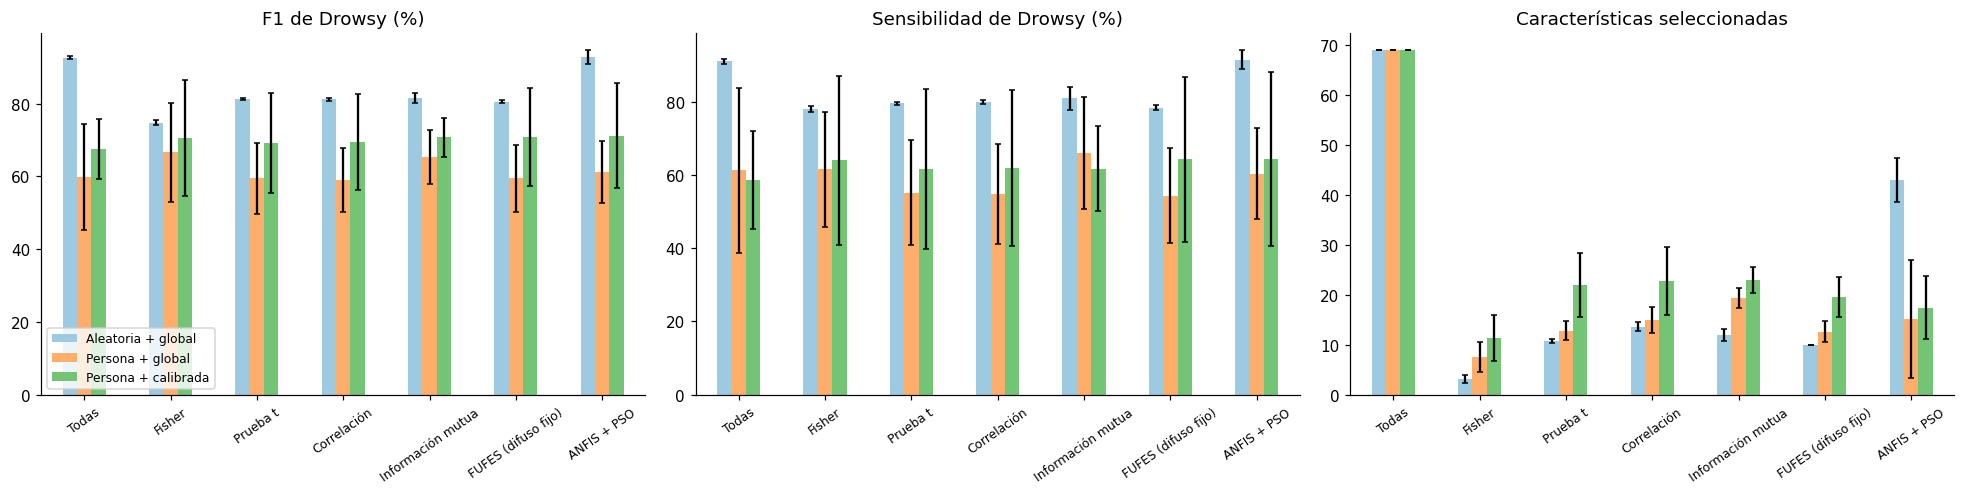

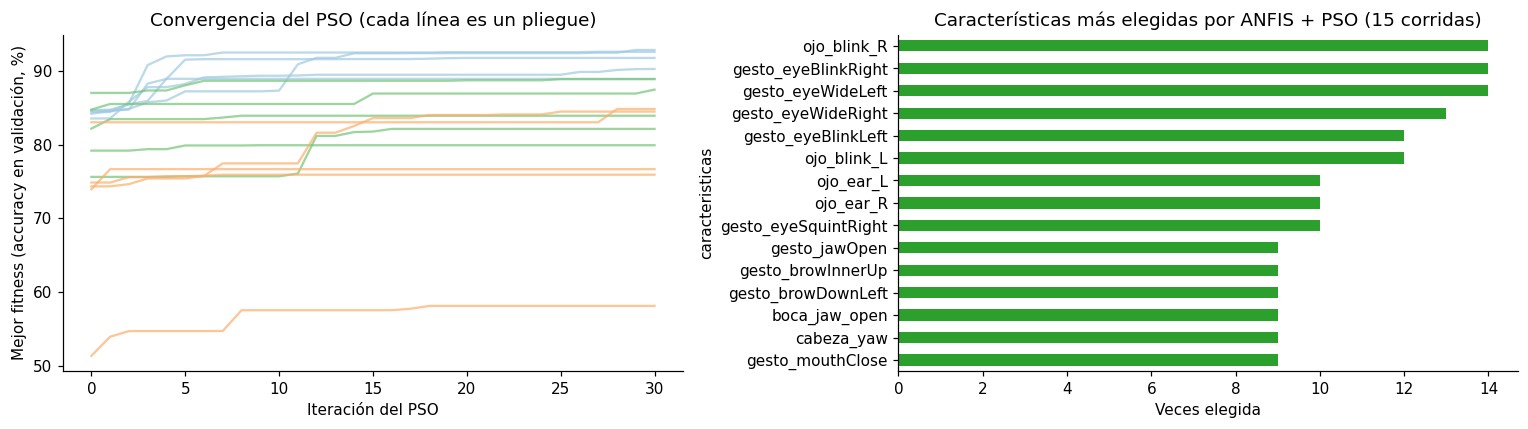

In [ ]:
ESC = list(ESCENARIOS); COLOR = ["#9ecae1", "#fdae6b", "#74c476"]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for k, (m, tit) in enumerate([("f1", "F1 de Drowsy (%)"), ("recall_drowsy", "Sensibilidad de Drowsy (%)"), ("n_caracteristicas", "Características seleccionadas")]):
    esc = 1 if m == "n_caracteristicas" else 100
    piv = E.groupby(["metodo", "escenario"])[m].mean().unstack()[ESC].reindex(af.METODOS) * esc
    err = E.groupby(["metodo", "escenario"])[m].std().unstack()[ESC].reindex(af.METODOS) * esc
    piv.plot.bar(yerr=err, ax=ax[k], capsize=2, color=COLOR, legend=(k == 0), rot=35)
    ax[k].set(title=tit, xlabel=""); ax[k].tick_params(axis="x", labelsize=8)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(CARPETA / "fig_anfis_experimento.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for j in J:
    ax[0].plot(np.array(j["curva_pso"]) * 100, color=COLOR[ESC.index(j["escenario"])], alpha=0.7)
ax[0].set(xlabel="Iteración del PSO", ylabel="Mejor fitness (accuracy en validación, %)", title="Convergencia del PSO (cada línea es un pliegue)")
sel = E[E.metodo == "ANFIS + PSO"]["caracteristicas"].str.split("|").explode().str.replace("x_", "").value_counts().head(15)
sel.plot.barh(ax=ax[1], color="#2ca02c"); ax[1].invert_yaxis(); ax[1].set(title="Características más elegidas por ANFIS + PSO (15 corridas)", xlabel="Veces elegida")
plt.tight_layout(); plt.savefig(CARPETA / "fig_anfis_pso.png", dpi=150); plt.show()

## 5. Análisis estadístico

- **ANOVA de dos factores** (método × escenario) sobre el F1 y la sensibilidad de Drowsy.
- **t de Student pareada** (dos colas, α = 0,05): ANFIS + PSO frente a cada método. Cada par es el mismo pliegue, así que comparte datos y personas.

In [ ]:
import statsmodels.api as smx
from statsmodels.formula.api import ols
from scipy import stats
for r, n in [("f1", "F1 de Drowsy"), ("recall_drowsy", "Sensibilidad de Drowsy")]:
    A = smx.stats.anova_lm(ols(f"{r} ~ C(metodo) * C(escenario)", data=E).fit(), typ=2)
    print(f"\n=== ANOVA de dos factores: {n} ==="); display(A.round(4))
filas = []
for esc in ESC:
    base = E[(E.escenario == esc) & (E.metodo == "ANFIS + PSO")].set_index("pliegue")
    for m in af.METODOS[:-1]:
        o = E[(E.escenario == esc) & (E.metodo == m)].set_index("pliegue").loc[base.index]
        fila = {"Escenario": esc, "ANFIS + PSO vs.": m}
        for r, n in [("f1", "F1"), ("recall_drowsy", "Sens. Drowsy")]:
            t, p = stats.ttest_rel(base[r], o[r])
            fila[f"Δ {n} (pts)"] = round((base[r] - o[r]).mean() * 100, 2); fila[f"p {n}"] = round(p, 4)
        filas.append(fila)
TP = pd.DataFrame(filas).set_index(["Escenario", "ANFIS + PSO vs."]); TP.to_csv(CARPETA / "t_pareada_anfis.csv"); TP


=== ANOVA de dos factores: F1 de Drowsy ===


,sum_sq,df,F,PR(>F)
C(metodo),0.0362,6.0,0.6698,0.6743
C(escenario),0.8636,2.0,47.9101,0.0000
C(metodo):C(escenario),0.1337,12.0,1.2366,0.2725
Residual,0.7571,84.0,NaN,NaN



=== ANOVA de dos factores: Sensibilidad de Drowsy ===


,sum_sq,df,F,PR(>F)
C(metodo),0.0633,6.0,0.4841,0.8185
C(escenario),1.1517,2.0,26.4138,0.0000
C(metodo):C(escenario),0.1122,12.0,0.4289,0.9477
Residual,1.8313,84.0,NaN,NaN


Δ F1 (pts)    p F1  \
Escenario           ANFIS + PSO vs.                           
Aleatoria + global  Todas                      0.14  0.8530   
                    Fisher                    18.10  0.0000   
                    Prueba t                  11.46  0.0001   
                    Correlación               11.57  0.0001   
                    Información mutua         11.22  0.0009   
                    FUFES (difuso fijo)       12.27  0.0001   
Persona + global    Todas                      1.53  0.7283   
                    Fisher                    -5.32  0.0995   
                    Prueba t                   1.82  0.2968   
                    Correlación                2.29  0.0713   
                    Información mutua         -4.17  0.2262   
                    FUFES (difuso fijo)        1.79  0.3506   
Persona + calibrada Todas                      3.78  0.5403   
                    Fisher                     0.61  0.8892   
                    Prueba t                   2.05  0.6997   
                    Correlación                1.75  0.7284   
                    Información mutua          0.53  0.9200   
                    FUFES (difuso fijo)        0.36  0.9550   

                                         Δ Sens. Drowsy (pts)  p Sens. Drowsy  
Escenario           ANFIS + PSO vs.                                            
Aleatoria + global  Todas                                0.49          0.5946  
                    Fisher                              13.48          0.0002  
                    Prueba t                            11.96          0.0003  
                    Correlación                         11.58          0.0003  
                    Información mutua                   10.55          0.0082  
                    FUFES (difuso fijo)                 13.06          0.0002  
Persona + global    Todas                               -0.85          0.9321  
                    Fisher                              -1.15          0.8350  
                    Prueba t                             5.26          0.3316  
                    Correlación                          5.55          0.2693  
                    Información mutua                   -5.68          0.2210  
                    FUFES (difuso fijo)                  6.07          0.2366  
Persona + calibrada Todas                                5.87          0.4734  
                    Fisher                               0.47          0.9407  
                    Prueba t                             2.73          0.6472  
                    Correlación                          2.48          0.6666  
                    Información mutua                    2.75          0.7161  
                    FUFES (difuso fijo)                  0.13          0.9848

## 6. Conclusiones

In [ ]:
m = E.groupby(["escenario", "metodo"])["f1"].mean().unstack()
for esc in ESC:
    print(f"{esc}: ANFIS + PSO F1 = {m.loc[esc, 'ANFIS + PSO']:.3f} | mejor método = {m.loc[esc].idxmax()} ({m.loc[esc].max():.3f}) | todas = {m.loc[esc, 'Todas']:.3f}")
a = E.groupby("escenario")["accuracy"].mean()
print(f"\nCaída por evaluar con personas nuevas (accuracy media): aleatoria {a['Aleatoria + global']:.3f} -> persona {a['Persona + global']:.3f}")

Aleatoria + global: ANFIS + PSO F1 = 0.928 | mejor método = ANFIS + PSO (0.928) | todas = 0.927
Persona + global: ANFIS + PSO F1 = 0.613 | mejor método = Fisher (0.666) | todas = 0.598
Persona + calibrada: ANFIS + PSO F1 = 0.713 | mejor método = ANFIS + PSO (0.713) | todas = 0.675

Caída por evaluar con personas nuevas (accuracy media): aleatoria 0.829 -> persona 0.621
